python -m venv .venv

.venv\Scripts\activate.bat

python -m pip install pandas numpy matplotlib seaborn scikit-learn scipy jupyter ipykernel

jupyter notebook

### Датасет содержит следующие колонки:

- `region` — административный округ Москвы.
- `district` — район расположения объекта.
- `street` — улица.
- `wall_material_code` — код материала стен; используется как категориальный признак, а не количественное число.
- `year_build` — год постройки дома.
- `floor` — этаж квартиры.
- `area` — общая площадь квартиры в квадратных метрах.
- `period_start_date` — дата начала периода наблюдения/сделки; из неё извлекается год `period_year`.
- `price` — цена объекта в рублях. Это целевой признак для задачи регрессии.

В качестве признаков используются числовые (`area`, `period_year`, `year_build`, `floor`) и категориальные (`region`, `district`, `street`, `wall_material_code`) признаки. Категориальные признаки кодируются: `region`, `district`, `wall_material_code` — one-hot, `street` — частотным кодированием.

# Прогнозирование стоимости квартир Москвы на N лет вперёд

**Задача:** оценивать стоимость квартиры по характеристикам и историческим данным рынка; изучать динамику медианной цены за м² отдельно по `region` и `district`; сравнивать модели на будущих относительно обучения годах; прогнозировать цену выбранной квартиры на заданное число лет.

Каждая кодовая ячейка предваряется текстом: что она делает, зачем нужна и как интерпретировать результат. Сохраняем графики EDA из исходного ноутбука, но исправляем подготовку данных и заменяем случайное разбиение на временную проверку.

**Методологическое ограничение:** если нет постоянного идентификатора объекта, нельзя подтвердить, что сделки разных лет относятся к одной и той же квартире. Поэтому оценка на отложенном годе проверяет качество предсказания цен сделок следующего периода, а прогноз конкретной квартиры на дальний срок является сценарной оценкой. Модель цены и тренд рынка будут показаны отдельно.

## Этап 1. Импорт библиотек и параметры проекта

Подключаем библиотеки для анализа, визуализации и машинного обучения. Укажите путь к CSV в `DATA_PATH`. Код поддерживает разделители `;` и `,`, а также типичные кодировки русскоязычных CSV.

In [1]:
from pathlib import Path
import warnings, time, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

DATA_PATH = Path("СДЕЛКИ_Мос_2015-2026.csv")  # измените путь при необходимости
RANDOM_STATE = 42

## Этап 2. Загрузка и проверка структуры данных

Считываем CSV и проверяем обязательные колонки. На этом шаге ничего не удаляем по порогам цены: аномально низкая цена может быть как ошибкой, так и реальной сделкой, и сначала её нужно диагностировать.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV не найден: {DATA_PATH.resolve()}\n"
        "Положите файл рядом с ноутбуком или укажите полный путь в DATA_PATH."
    )

read_error = None
for sep in [None, ";", ",", "\\t"]:
    for encoding in ["utf-8-sig", "cp1251"]:
        try:
            if sep is None:
                loaded = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding=encoding)
            else:
                loaded = pd.read_csv(DATA_PATH, sep=sep, encoding=encoding)
            if loaded.shape[1] >= 5:
                df_raw = loaded.copy()
                break
        except Exception as exc:
            read_error = exc
    else:
        continue
    break
else:
    raise RuntimeError(f"Не удалось прочитать CSV. Последняя ошибка: {read_error}")

df_raw.columns = df_raw.columns.astype(str).str.strip().str.lower()
expected_cols = ["region", "district", "street", "wall_material_code",
                 "year_build", "floor", "area", "period_start_date", "price"]
missing = [c for c in expected_cols if c not in df_raw.columns]
if missing:
    raise ValueError(f"Не найдены колонки {missing}. В файле есть: {df_raw.columns.tolist()}")

print(f"Файл: {DATA_PATH.resolve()}")
print(f"Размер до очистки: {df_raw.shape[0]:,} строк × {df_raw.shape[1]} колонок")
display(df_raw.head())
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum()}))

Файл: C:\Users\AnnaA\Desktop\Система прогнозирования\СДЕЛКИ_Мос_2015-2026.csv
Размер до очистки: 45,657 строк × 9 колонок


,region,district,street,wall_material_code,year_build,floor,area,period_start_date,price
0,САО,Бескудниковский,Дмитровское,61001007004,1966.0,12,64,01.01.2024,18981000
1,САО,Головинский,Кронштадтский,61001007001,1974.0,7,63,01.01.2024,14700000
2,САО,Левобережный,Ленинградское,61001006001,2007.0,2,94,01.01.2024,29500000
3,САО,Беговой,Расковой,61001007004,1963.0,3,45,01.01.2024,15500000
4,САО,Коптево,Большая Академическая,61001007001,2010.0,15,38,01.01.2024,10100000


,dtype,missing
region,str,0
district,str,0
street,str,0
wall_material_code,int64,0
year_build,float64,22
floor,int64,0
area,str,0
period_start_date,str,0
price,str,0


## Этап 3. Очистка без потери подозрительно дешёвых сделок

Удаляем полные дубликаты, нормализуем строки и преобразуем числа/даты. Исключаем только физически невозможные или непригодные записи (например, нулевая площадь или цена). **Не задаём правило `price > 7 000 000`**: оно систематически удалило бы дешёвые квартиры и исказило рынок. Сохраняем `price_per_sqm` для диагностики и временного анализа.

In [3]:
df = df_raw.drop_duplicates().copy()
print("Удалено полных дубликатов:", len(df_raw) - len(df))

text_cols = ["region", "district", "street", "wall_material_code"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

def clean_numeric(series):
    s = (series.astype("string")
         .str.replace("\u00a0", "", regex=False)
         .str.replace(" ", "", regex=False)
         .str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

for col in ["year_build", "floor", "area", "price"]:
    df[col] = clean_numeric(df[col])
df["period_start_date"] = pd.to_datetime(df["period_start_date"], errors="coerce", dayfirst=True)
df["period_year"] = df["period_start_date"].dt.year

df = df[(df['area'] > 25) & (df['price'] > 7_000_000)].copy().reset_index(drop=True)

before = len(df)
df = df.dropna(subset=["period_start_date", "price", "area", "year_build", "floor"]).copy()
print("Удалено строк без обязательных даты/цены/площади/этажа/года постройки:", before-len(df))

current_year = pd.Timestamp.today().year
valid = (
    (df["price"] > 0) & (df["area"] > 0) & (df["floor"] >= 1) &
    (df["year_build"].between(1800, current_year + 5)) &
    (df["period_year"].between(1900, current_year + 1)) &
    (df["year_build"] <= df["period_year"] + 1)
)
before = len(df)
df = df.loc[valid].copy()
print("Удалено физически некорректных значений:", before-len(df))

df["year_build"] = df["year_build"].round().astype(int)
df["floor"] = df["floor"].round().astype(int)
df["period_year"] = df["period_year"].astype(int)
df["price"] = df["price"].astype(float)
df["price_per_sqm"] = df["price"] / df["area"]
df["building_age"] = (df["period_year"] - df["year_build"]).clip(lower=0)
df = df.replace([np.inf, -np.inf], np.nan).reset_index(drop=True)

print(f"После базовой очистки: {len(df):,} строк")
display(df[["price", "area", "price_per_sqm"]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

Удалено полных дубликатов: 4113
Удалено строк без обязательных даты/цены/площади/этажа/года постройки: 2
Удалено физически некорректных значений: 0
После базовой очистки: 40,134 строк


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,40134.0,50201442.942779,1420275868.339934,7003035.0,8000000.0,9150000.0,12310224.25,16845907.0,25000000.0,72500000.0,190000000.0,150336000000.0
area,40134.0,54.148343,24.743423,26.0,28.0,32.0,38.0,47.0,61.0,107.0,155.0,187.0
price_per_sqm,40134.0,976653.297721,38349733.940531,101375.042254,206044.721365,226607.285638,279918.478261,344827.586207,470482.488823,944541.225806,2022547.209412,4555636363.636364


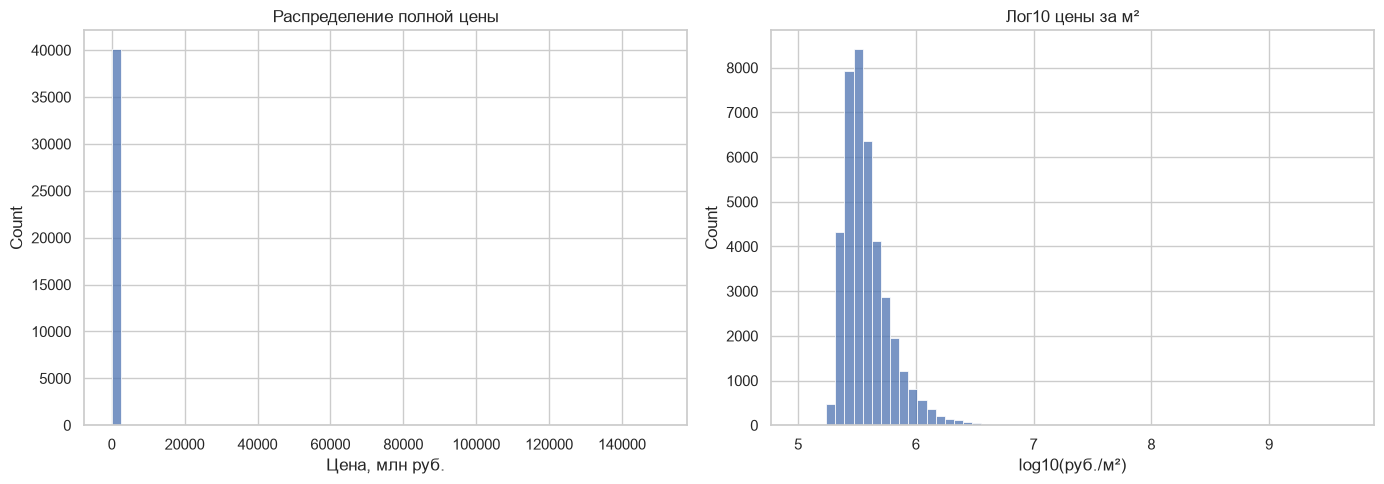

Ниже 1-го процентиля цены за м² своего года: 405 строк (1.01%).


,period_start_date,region,district,street,year_build,floor,area,price,price_per_sqm
40126,2016-04-05,НАО,Сосенское,Ясная,1994,16,71.0,7197628.0,101375.042254
40132,2018-01-11,САО,Хорошевский,Хорошевское,1993,2,121.3,20136159.5,166002.963726
40129,2017-10-30,НАО,Первомайское,Парковая,1992,11,85.0,15915308.0,187238.917647
11478,2024-10-01,ВАО,Измайлово,Измайловский,2000,7,38.0,7500000.0,197368.421053
13589,2024-10-01,ВАО,Гольяново,Байкальская,1969,3,42.0,8300000.0,197619.047619
24997,2025-10-01,ВАО,Измайлово,Измайловский,1963,3,43.0,8500000.0,197674.418605
11156,2024-10-01,ЦАО,Мещанский,Банный,1966,1,43.0,8500000.0,197674.418605
1659,2024-01-01,ВАО,Гольяново,Байкальская,1968,4,48.0,9500000.0,197916.666667
21080,2025-07-01,ВАО,Вешняки,Вешняковская,1973,11,49.0,9700000.0,197959.183673
29,2024-01-01,САО,Сокол,Песчаный,1966,5,49.0,9700000.0,197959.183673


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["price"]/1e6, bins=60, ax=axes[0])
axes[0].set_title("Распределение полной цены")
axes[0].set_xlabel("Цена, млн руб.")
sns.histplot(np.log10(df.loc[df["price_per_sqm"] > 0, "price_per_sqm"]), bins=60, ax=axes[1])
axes[1].set_title("Лог10 цены за м²")
axes[1].set_xlabel("log10(руб./м²)")
plt.tight_layout(); plt.show()

# Робастный флаг: нижний 1-й процентиль цены за м² внутри года.
year_q01 = df.groupby("period_year")["price_per_sqm"].transform(lambda s: s.quantile(0.01))
df["flag_low_ppsqm_year"] = df["price_per_sqm"] < year_q01
low_flags = df.loc[df["flag_low_ppsqm_year"],
                   ["period_start_date","region","district","street","year_build","floor","area","price","price_per_sqm"]]
print(f"Ниже 1-го процентиля цены за м² своего года: {len(low_flags):,} строк ({len(low_flags)/len(df):.2%}).")
display(low_flags.sort_values("price_per_sqm").head(30))

## Этап 5. Решение по выбросам и создание аналитической таблицы

Посмотрите на отмеченные строки и сверьте их с источником. Если выявлены ошибки (например, лишний/пропущенный ноль, цена указана не в рублях), исправьте первоисточник. Если подтвердить ошибку нельзя, оставьте строку и сравните качество моделей с ней и без неё. Ниже используем консервативный режим: все положительные цены остаются, а флаг сохраняется как диагностический признак. По желанию можно включить робастное ограничение для обучения, но пороги должны определяться по предметному смыслу и только на обучающих данных.

Используются все прошедшие базовую проверку сделки; подозрительные цены только помечены.


,period_year,deals,median_price,median_ppsqm
0,2015,3,22390753.00,419396.53
1,2016,35,17948636.00,452175.98
2,2017,14,16588795.50,328049.32
3,2018,2,20136159.75,166002.97
4,2019,790,19864828.00,451964.36
5,2020,2,15624114.00,473937.93
6,2021,7,24078457.00,294904.45
7,2022,1524,20021884.00,385727.66
8,2023,1523,20031615.00,385727.66
9,2024,14180,15500000.00,320339.18


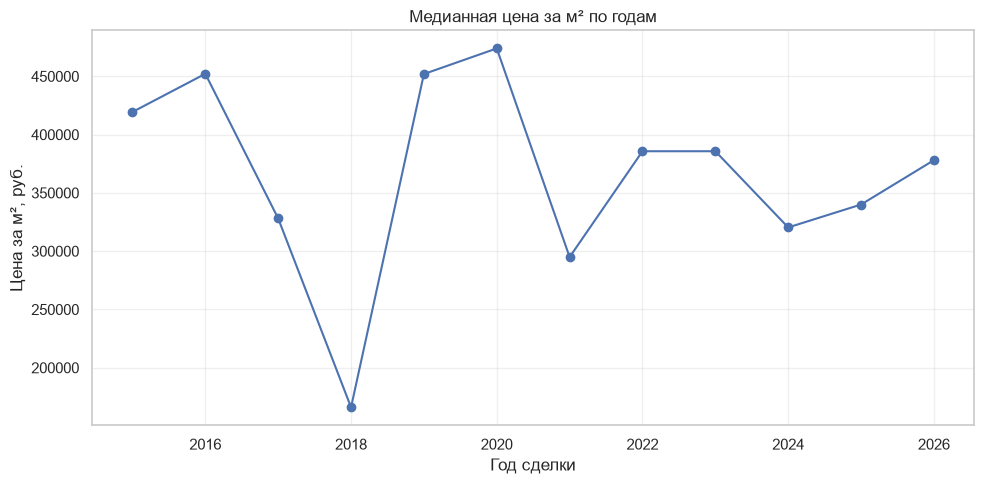

In [5]:
# По умолчанию подозрительные низкие цены НЕ удаляются.
REMOVE_FLAGGED_LOW_PRICES_FOR_MODEL = False

model_source = df.copy()
if REMOVE_FLAGGED_LOW_PRICES_FOR_MODEL:
    # Только как эксперимент чувствительности, не как рекомендация по умолчанию.
    model_source = model_source.loc[~model_source["flag_low_ppsqm_year"]].copy()
    print("Эксперимент: удалены записи ниже годового 1-го процентиля цены за м².")
else:
    print("Используются все прошедшие базовую проверку сделки; подозрительные цены только помечены.")

# Обзор цены за м² по годам и регионам
year_summary = (model_source.groupby("period_year")
                .agg(deals=("price","size"),
                     median_price=("price","median"),
                     median_ppsqm=("price_per_sqm","median"))
                .reset_index())
display(year_summary.round(2))
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(year_summary["period_year"], year_summary["median_ppsqm"], marker="o")
ax.set_title("Медианная цена за м² по годам")
ax.set_xlabel("Год сделки"); ax.set_ylabel("Цена за м², руб.")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

### Разведочный анализ данных (EDA)

## Цена квартиры в зависимости от материала стен

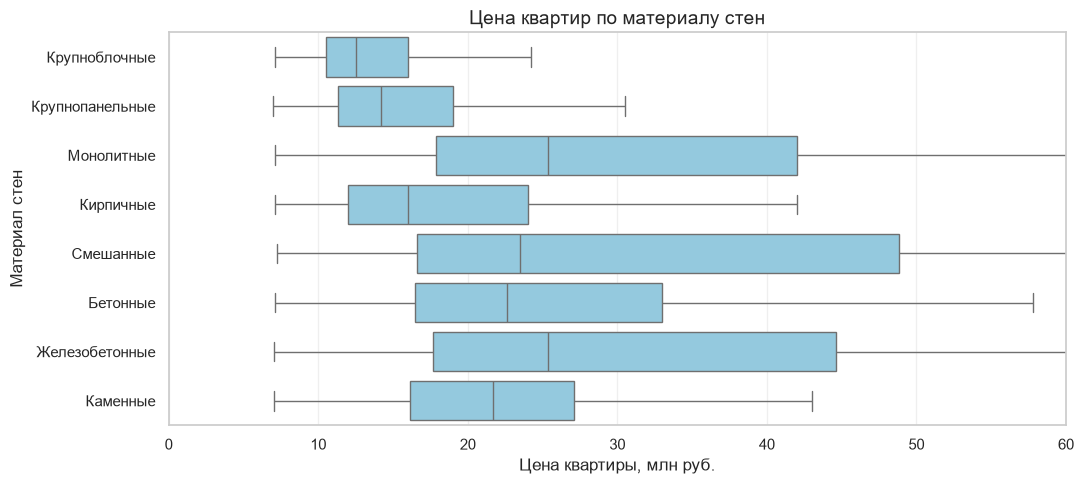

,median_price_mln_rub
wall_material,
Крупноблочные,12.50
Крупнопанельные,14.20
Кирпичные,16.00
Каменные,21.72
Бетонные,22.63
Смешанные,23.50
Железобетонные,25.35
Монолитные,25.39


In [6]:
# Сравниваем цену по материалу стен (шкала — в млн руб., до 100 млн)
# Словарь соответствия кода материала стен его названию
WALL_MATERIAL_NAMES = {
    '61001001000': 'Каменные',
    '61001001001': 'Кирпичные',
    '61001003000': 'Смешанные',
    '61001006000': 'Бетонные',
    '61001006001': 'Монолитные',
    '61001007000': 'Железобетонные',
    '61001007001': 'Крупнопанельные',
    '61001007004': 'Крупноблочные',
}
plot_df = df.dropna(subset=['wall_material_code', 'price']).copy()
plot_df['price_mln'] = plot_df['price'] / 1_000_000
# Заменяем коды стен их названиями, чтобы подписи на диаграмме были читаемыми
plot_df['wall_material'] = plot_df['wall_material_code'].map(WALL_MATERIAL_NAMES).fillna('Прочие')
median_prices = plot_df.groupby('wall_material')['price_mln'].median().sort_values()

if not median_prices.empty:
    plt.figure(figsize=(11, max(5, 0.35 * len(median_prices))))
    ax = sns.boxplot(data=plot_df, y='wall_material', x='price_mln', color='skyblue', showfliers=False)
    plt.title('Цена квартир по материалу стен', fontsize=14)
    plt.xlabel('Цена квартиры, млн руб.')
    plt.ylabel('Материал стен')
    ax.set_xlim(0, 60)  # шкала цены — до 100 млн руб.
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(median_prices.rename('median_price_mln_rub').round(2).to_frame())
else:
    print('Нет данных для графика по материалу стен.')

На графике можно сравнить распределение цен по материалам стен (на диаграмме подписаны материалы, а не коды). Шкала цены ограничена 100 млн руб. Разницу и её величину нужно интерпретировать по фактическому графику после запуска; заранее заданные проценты не используются.

### Цена квартиры в зависимости от района

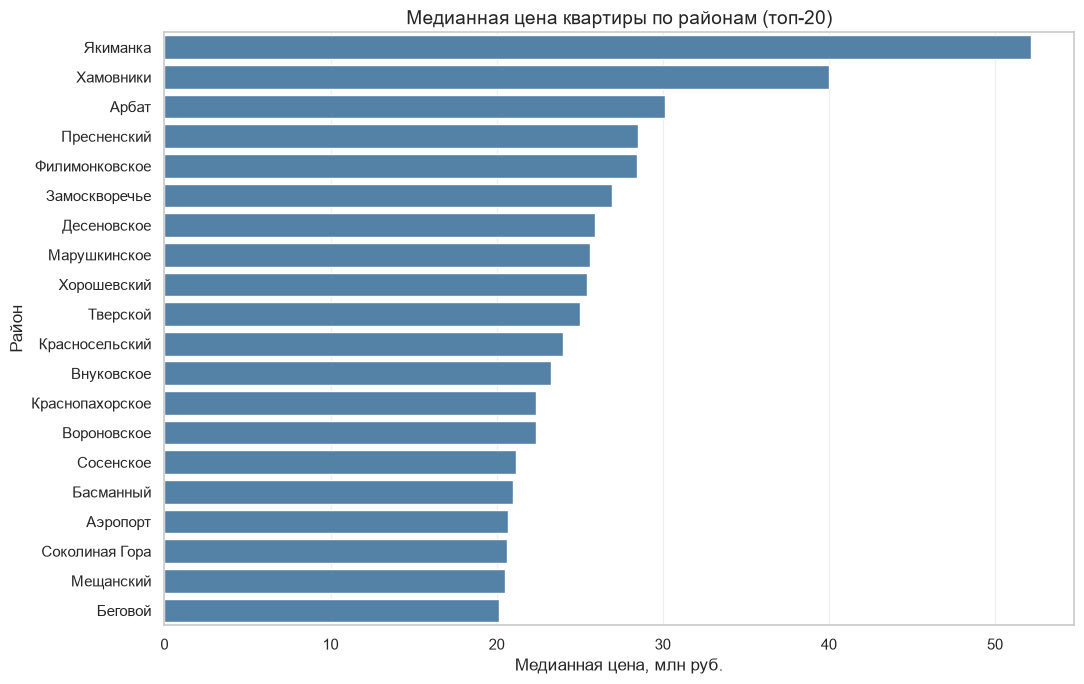

,median_price_mln_rub,object_count
district,,
Якиманка,52.15,529
Хамовники,40.00,721
Арбат,30.13,219
Пресненский,28.50,1926
Филимонковское,28.44,1
Замоскворечье,26.98,393
Десеновское,25.90,1
Марушкинское,25.60,1
Хорошевский,25.42,2189


In [7]:
# Медианная цена по районам (в млн рублей)
plot_df = df.dropna(subset=['district', 'price']).copy()

stats = (
    plot_df.groupby('district')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .head(20)
)

# Переводим медианную цену из рублей в млн рублей
stats['median'] = stats['median'] / 1_000_000

plt.figure(figsize=(11, max(5, 0.35 * len(stats))))

ax = sns.barplot(
    x=stats['median'].values,
    y=stats.index.astype(str),
    color='steelblue'
)

plt.title('Медианная цена квартиры по районам (топ-20)', fontsize=14)
plt.xlabel('Медианная цена, млн руб.')
plt.ylabel('Район')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(
    stats.rename(columns={
        'median': 'median_price_mln_rub',
        'count': 'object_count'
    }).round({'median_price_mln_rub': 2})
)

На графике показана медианная цена по районам. Вывод о том, какие районы дороже, делается по результатам фактического расчёта на загруженном датасете.

Далее посмотрим, как площадь квартиры связана со стоимостью.

### Цена квартиры в зависимости от площади

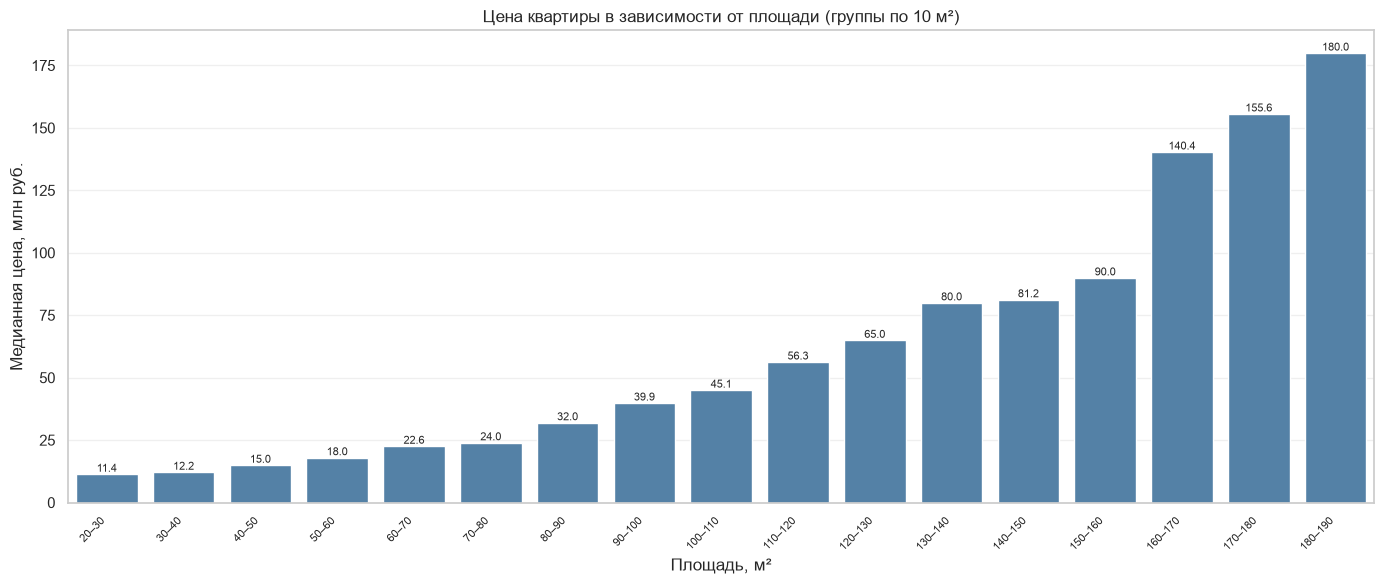

In [8]:
# Делим площадь на группы по 10 м² (цена — в млн руб.)
plot_df = df.dropna(subset=['area', 'price']).copy()
if plot_df['area'].nunique() >= 2:
    # Интервалы по 10 м²
    bins = list(range(0, 301, 10))
    plot_df['area_category'] = pd.cut(plot_df['area'], bins=bins)
    stats = plot_df.groupby('area_category', observed=True)['price'].median() / 1_000_000
    stats = stats.dropna()
    x_labels = [f'{int(interval.left)}–{int(interval.right)}' for interval in stats.index]

    plt.figure(figsize=(14, 6))
    ax = sns.barplot(x=x_labels, y=stats.values, color='steelblue')
    plt.title('Цена квартиры в зависимости от площади (группы по 10 м²)')
    plt.xlabel('Площадь, м²')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно различных значений площади для построения групп.')


Сравнение медианной цены по группам площади позволяет оценить связь площади и стоимости. Конкретные выводы делаются после построения графика.

### Стоимость квартир в зависимости от этажа

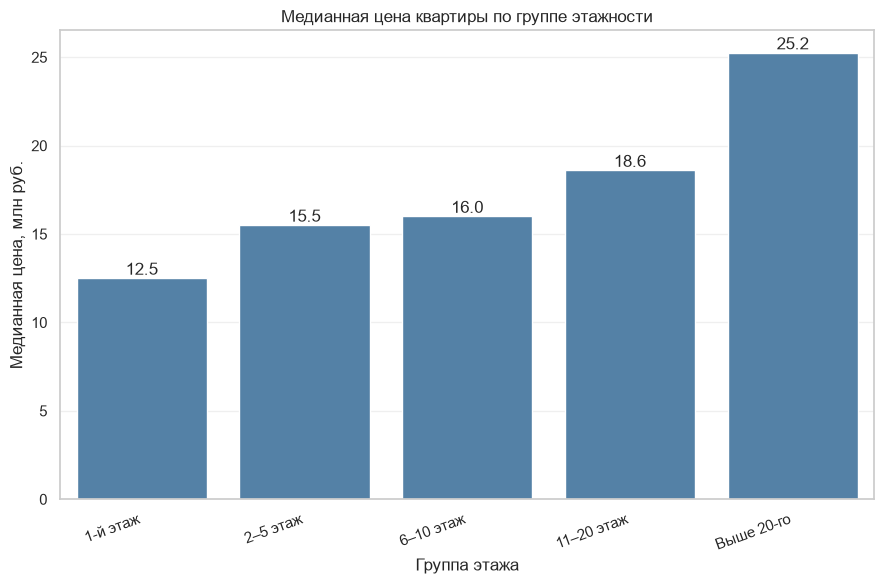

In [9]:
# Здесь floor — фактический номер этажа, а не бинарный признак (цена — в млн руб.)
plot_df = df.dropna(subset=['floor', 'price']).copy()
plot_df['floor_group'] = pd.cut(
    plot_df['floor'], bins=[0, 1, 5, 10, 20, np.inf],
    labels=['1-й этаж', '2–5 этаж', '6–10 этаж', '11–20 этаж', 'Выше 20-го'],
    include_lowest=True
)
stats = plot_df.groupby('floor_group', observed=True)['price'].median() / 1_000_000

if not stats.empty:
    plt.figure(figsize=(9, 6))
    ax = sns.barplot(x=stats.index.astype(str), y=stats.values, color='steelblue')
    plt.title('Медианная цена квартиры по группе этажности')
    plt.xlabel('Группа этажа')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Нет данных для анализа этажа.')


График сравнивает медианную цену объектов по этажам. Различия не следует заранее задавать фиксированными процентами: они рассчитываются по фактическим данным.

### Корреляционный анализ

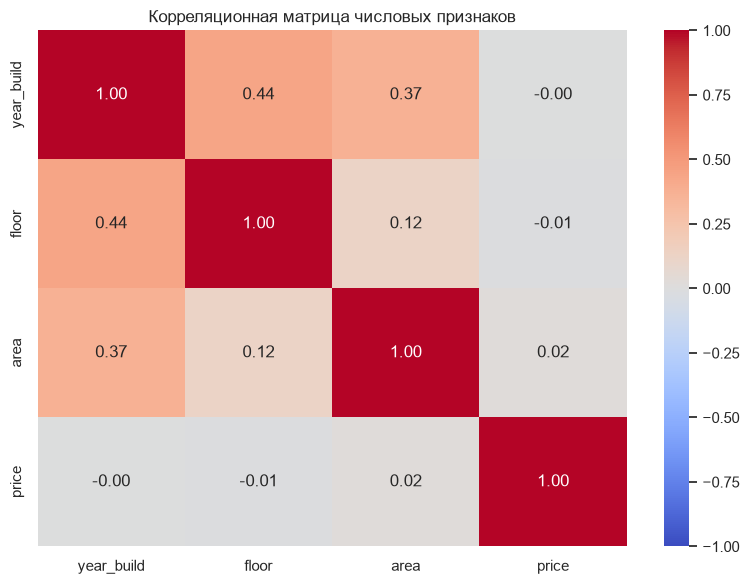

Корреляция признаков с целевой переменной price:
price         1.000
area          0.019
year_build   -0.002
floor        -0.013
Name: price, dtype: float64


In [10]:
# Для корреляции используем числовые признаки и целевую переменную
numeric_cols = ['year_build', 'floor', 'area', 'price']
df_corr = df[numeric_cols].copy()
corr_matrix = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевой переменной price:')
print(corr_matrix['price'].sort_values(ascending=False).round(3))


In [11]:
# Интерпретация корреляции: линейная связь между исходными признаками и полной ценой.
# Корреляция Пирсона не измеряет причинность и не учитывает нелинейность/состав объектов.
# Коэффициент крайне чувствителен к выбросам: даже несколько экстремальных записей могут
# сильно исказить результат (вплоть до почти нулевого значения при реальной зависимости).
from IPython.display import Markdown, display

def ru_num(x, nd=3):
    return f'{x:.{nd}f}'.replace('.', ',')

corr_with_price = (df[['year_build', 'floor', 'area', 'price']]
                   .corr(numeric_only=True)['price']
                   .drop('price')
                   .sort_values(ascending=False))
feat_names = {'area': 'площадью квартиры', 'year_build': 'годом постройки', 'floor': 'этажом'}

def strength(r):
    if abs(r) >= 0.5: return 'заметная'
    if abs(r) >= 0.3: return 'умеренная'
    if abs(r) >= 0.1: return 'слабая'
    return 'очень слабая'

lines = ["### Вывод по корреляционному анализу",
         "Корреляция Пирсона показывает только **линейную** связь каждого числового признака с полной ценой квартиры; она не является доказательством причинно-следственной связи. Коэффициент крайне чувствителен к выбросам и неоднородности данных, поэтому в такой выборке его нужно интерпретировать вместе с графиками и медианными показателями, а не как самостоятельную меру важности признака."]
for col, r in corr_with_price.items():
    if col == 'area' and abs(r) < 0.1:
        explanation = ("Связь площади и полной цены получилась практически нулевой (r ≈ 0), что необычно для типичного рынка. "
                       "Наиболее вероятная причина — сильные выбросы и неоднородность выборки: в данных встречаются записи "
                       "с ценой порядка миллиардов рублей при площади 30–50 м² и площади в тысячи м² при минимальной цене. "
                       "В этом ноутбуке такие записи консервативно не удаляются, а только помечаются флагом (см. Этап 5), "
                       "поэтому они продолжают искажать коэффициент Пирсона. Корреляция не учитывает разные сегменты рынка "
                       "(округ, год сделки) и не ловит нелинейную зависимость, которую способны улавливать деревья решений. "
                       "Слабая корреляция не означает, что площадь не важна: проверьте scatter plot «площадь — цена», "
                       "медианную цену по диапазонам площади и цену за м², а также метрики модели после удаления аномалий.")
    else:
        explanation = f"Линейная связь с полной ценой — {strength(r)}."
    lines.append(f"- **{feat_names.get(col, col)}**: r = {ru_num(r)}. {explanation}")
lines.append("")
lines.append("Важно: полная цена обычно зависит от площади, но коэффициент корреляции может быть близок к нулю, если данные содержат сильные ошибки, неоднородные группы и экстремальные значения. Корреляция Пирсона также может пропускать нелинейную связь.")
display(Markdown("\\n".join(lines)))

### Вывод по корреляционному анализу\nКорреляция Пирсона показывает только **линейную** связь каждого числового признака с полной ценой квартиры; она не является доказательством причинно-следственной связи. Коэффициент крайне чувствителен к выбросам и неоднородности данных, поэтому в такой выборке его нужно интерпретировать вместе с графиками и медианными показателями, а не как самостоятельную меру важности признака.\n- **площадью квартиры**: r = 0,019. Связь площади и полной цены получилась практически нулевой (r ≈ 0), что необычно для типичного рынка. Наиболее вероятная причина — сильные выбросы и неоднородность выборки: в данных встречаются записи с ценой порядка миллиардов рублей при площади 30–50 м² и площади в тысячи м² при минимальной цене. В этом ноутбуке такие записи консервативно не удаляются, а только помечаются флагом (см. Этап 5), поэтому они продолжают искажать коэффициент Пирсона. Корреляция не учитывает разные сегменты рынка (округ, год сделки) и не ловит нелинейную зависимость, которую способны улавливать деревья решений. Слабая корреляция не означает, что площадь не важна: проверьте scatter plot «площадь — цена», медианную цену по диапазонам площади и цену за м², а также метрики модели после удаления аномалий.\n- **годом постройки**: r = -0,002. Линейная связь с полной ценой — очень слабая.\n- **этажом**: r = -0,013. Линейная связь с полной ценой — очень слабая.\n\nВажно: полная цена обычно зависит от площади, но коэффициент корреляции может быть близок к нулю, если данные содержат сильные ошибки, неоднородные группы и экстремальные значения. Корреляция Пирсона также может пропускать нелинейную связь.

## Этап 6. Подготовка признаков для моделей

Для цены используем исходные характеристики квартиры, год сделки и возраст дома на момент сделки. Категориальные признаки кодируются внутри `Pipeline`, чтобы кодирование обучалось только на обучающей выборке и не заглядывало в тест. Цель обучения — `log1p(price)`: логарифм делает обучение менее чувствительным к очень дорогим объектам; предсказания затем переводятся обратно в рубли.

`street` включаем как категориальный признак. Если улиц очень много, one-hot кодирование может быть объёмным, но оно не присваивает улицам ложный числовой порядок.

In [12]:
model_df = model_source.copy()
for col in ["region", "district", "street", "wall_material_code"]:
    model_df[col] = model_df[col].astype("string").fillna("Неизвестно").astype(str)

categorical_cols = ["region", "district", "street", "wall_material_code"]
numeric_cols = ["year_build", "floor", "area", "period_year", "building_age"]
feature_cols = categorical_cols + numeric_cols
model_df = model_df.dropna(subset=["price", "period_year", "area"]).sort_values("period_start_date").reset_index(drop=True)

try:
    onehot = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse=False)

preprocessor = ColumnTransformer([
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", onehot)]), categorical_cols),
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_cols)
], remainder="drop")

print("Строк для моделирования:", len(model_df))
print("Категориальные признаки:", categorical_cols)
print("Числовые признаки:", numeric_cols)
display(model_df[feature_cols + ["price","price_per_sqm"]].head())

Строк для моделирования: 40134
Категориальные признаки: ['region', 'district', 'street', 'wall_material_code']
Числовые признаки: ['year_build', 'floor', 'area', 'period_year', 'building_age']


,region,district,street,wall_material_code,year_build,floor,area,period_year,building_age,price,price_per_sqm
0,НАО,Сосенское,Ясная,61001001001,1993,6,45.0,2015,22,13610197.0,302448.822222
1,НАО,Сосенское,Ясная,61001006000,1996,3,62.0,2015,19,26002585.0,419396.532258
2,ТАО,Краснопахорское,Ленина,61001006000,1999,18,47.0,2015,16,22390753.0,476399.0
3,НАО,Сосенское,Ясная,61001001001,1994,16,71.0,2016,22,7197628.0,101375.042254
4,НАО,Сосенское,Ясная,61001006000,1991,2,51.0,2016,25,26001130.0,509826.078431


## Этап 7. Временное разделение: обучаемся на прошлом, проверяем на будущем

Случайное разбиение здесь не подходит: оно может поместить сделки одного года и в обучение, и в тест, а это делает оценку слишком оптимистичной. Основной тест — последний доступный год строго меньше 2026 года. Модель обучается только на годах до тестового. Для содержательной оценки необходимо достаточно данных минимум за два года до 2026-го.

In [13]:
available_years = sorted(int(y) for y in model_df["period_year"].dropna().unique() if int(y) < 2026)
if len(available_years) < 2:
    raise ValueError("Нужно не менее двух разных годов сделок до 2026 года.")
test_year = available_years[-1]
train_df = model_df[model_df["period_year"] < test_year].copy()
test_df = model_df[model_df["period_year"] == test_year].copy()

if len(train_df) < 30 or len(test_df) < 5:
    candidates = [y for y in available_years[1:]
                  if (model_df["period_year"] < y).sum() >= 30 and (model_df["period_year"] == y).sum() >= 5]
    if candidates:
        test_year = candidates[-1]
        train_df = model_df[model_df["period_year"] < test_year].copy()
        test_df = model_df[model_df["period_year"] == test_year].copy()

if train_df.empty or test_df.empty:
    raise ValueError("Не удалось сформировать временные train/test выборки. Проверьте годы в period_start_date.")

X_train, y_train = train_df[feature_cols], np.log1p(train_df["price"].astype(float))
X_test, y_test = test_df[feature_cols], test_df["price"].astype(float)

print(f"Год тестирования: {test_year}")
print(f"Обучение: годы {train_df.period_year.min()}–{train_df.period_year.max()}, строк {len(train_df):,}")
print(f"Тест: {test_year}, строк {len(test_df):,}")

Год тестирования: 2025
Обучение: годы 2015–2024, строк 18,080
Тест: 2025, строк 14,891


## Этап 8. Обучение модели с заранее известными параметрами

Лучшие параметры уже определены ранее, поэтому повторный поиск гиперпараметров и сравнение нескольких моделей не выполняются. Здесь сразу обучается `HistGradientBoostingRegressor` с фиксированными параметрами. Далее эта модель используется для оценки прогнозов, исторического backtest и прогноза на будущие годы.

In [14]:
# Лучшие параметры заданы заранее — повторный поиск и сравнение моделей не нужны.
from sklearn.ensemble import HistGradientBoostingRegressor

KNOWN_BEST_PARAMS = {
    "model__max_leaf_nodes": 63,
    "model__max_iter": 150,
    "model__learning_rate": 0.08,
    "model__l2_regularization": 1.0
}
best_model_name = "HistGradientBoosting"

best_estimator_fixed = HistGradientBoostingRegressor(
    max_leaf_nodes=KNOWN_BEST_PARAMS["model__max_leaf_nodes"],
    max_iter=KNOWN_BEST_PARAMS["model__max_iter"],
    learning_rate=KNOWN_BEST_PARAMS["model__learning_rate"],
    l2_regularization=KNOWN_BEST_PARAMS["model__l2_regularization"],
    random_state=RANDOM_STATE
)
best_pipeline_fixed = Pipeline([("prep", preprocessor), ("model", best_estimator_fixed)])
best_pipeline_fixed.fit(X_train, y_train)

# Совместимость с последующими ячейками, которые используют best_search.best_estimator_.
best_search = type("FixedBestModel", (), {})()
best_search.best_estimator_ = best_pipeline_fixed
best_search.best_params_ = KNOWN_BEST_PARAMS

print("Модель обучена с заранее заданными параметрами:")
display(pd.DataFrame({"Параметр": list(KNOWN_BEST_PARAMS.keys()),
                      "Значение": list(KNOWN_BEST_PARAMS.values())}))


Модель обучена с заранее заданными параметрами:


,Параметр,Значение
0,model__max_leaf_nodes,63.00
1,model__max_iter,150.00
2,model__learning_rate,0.08
3,model__l2_regularization,1.00


## Этап 9. Почему выбрана эта модель: сравнение графиками и точность по каждому объекту

На всех графиках полной стоимости используется шкала **млн рублей** с максимумом **200 млн руб.** Сравниваем MAE и RMSE в млн рублей, MAPE в процентах, затем строим диаграмму «факт против прогноза», график остатков и столбчатую диаграмму фактической/прогнозной цены для первых 10 тестовых квартир. Для каждого объекта показываются абсолютная ошибка в млн рублей, абсолютная процентная ошибка и условная процентная точность `max(0, 100 − процентная ошибка)`. Единый показатель точности прогнозов — `Accuracy = 100% − MAPE`.

Важно: процентная точность по объекту — наглядная производная метрика, а не стандартная универсальная мера. Основной процентный показатель для сравнения — MAPE. Отрицательный R² означает, что на данном тестовом наборе модель проиграла наивному прогнозу средним значением тестовых цен; это сигнал изучить аномалии и качество признаков.

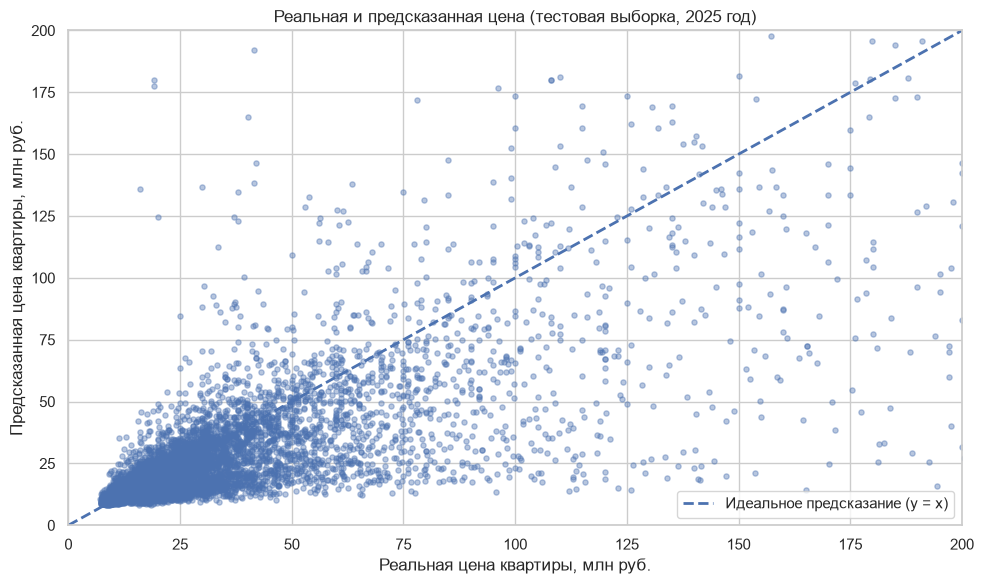

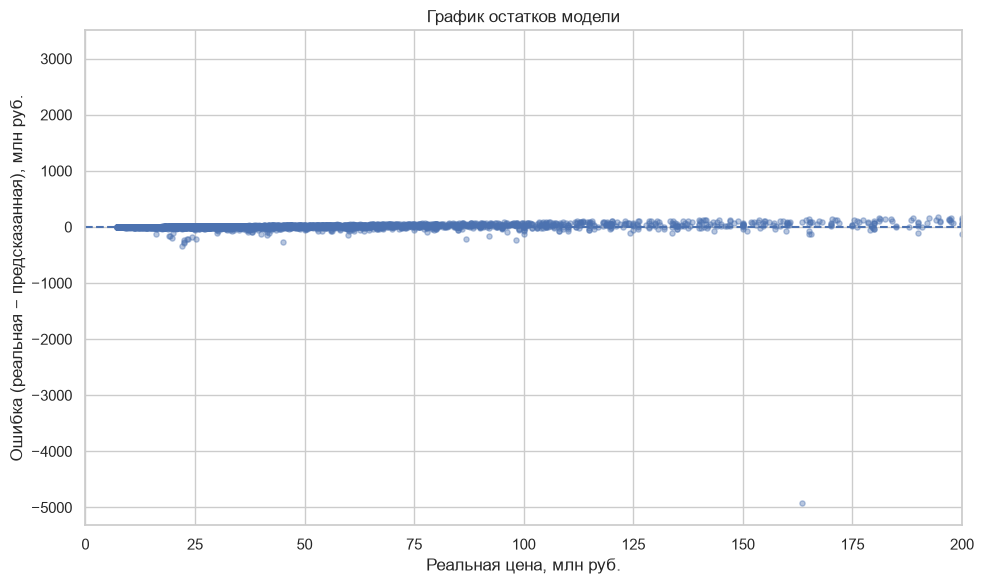

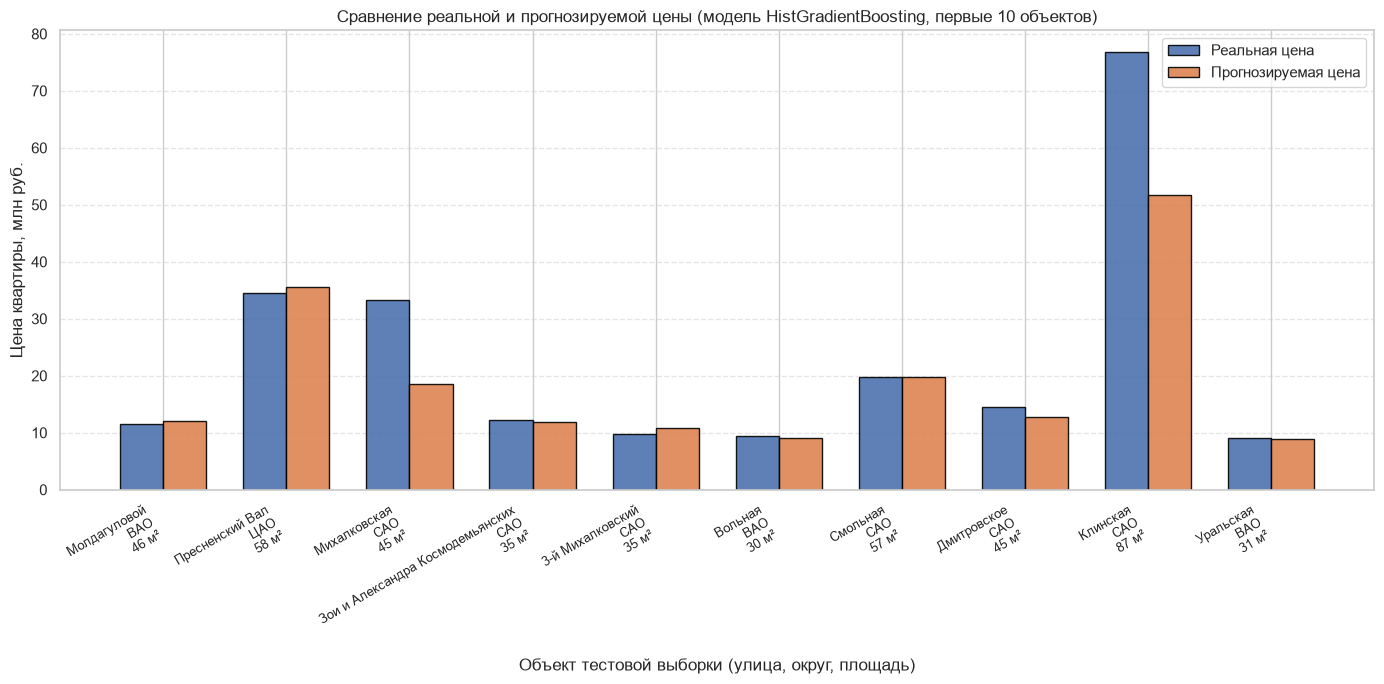

,"MAE, млн руб.","RMSE, млн руб.","MAPE, %","Средняя процентная точность, %",R²
0,9.87,89.94,20.81,80.82,-2.1



Статистика ошибок модели (в млн руб.):
MAE = 9.87 млн руб.
Максимальная абсолютная ошибка = 4917.32 млн руб.
Средняя ошибка = 3.14 млн руб.

Относительные показатели:
MAPE = 20.81%

Точность прогнозов (accuracy):
Accuracy = 79.2%


,street,region,area,"Факт, млн руб.","Прогноз, млн руб.","Абсолютная ошибка, млн руб.","Процентная ошибка, %","Процентная точность, %"
18080,Молдагуловой,ВАО,46.0,11.45,12.11,0.66,5.74,94.26
18081,Пресненский Вал,ЦАО,58.0,34.50,35.59,1.09,3.15,96.85
18082,Михалковская,САО,45.0,33.35,18.59,14.76,44.25,55.75
18083,Зои и Александра Космодемьянских,САО,35.0,12.30,11.90,0.40,3.27,96.73
18084,3-й Михалковский,САО,35.0,9.80,10.77,0.97,9.92,90.08
18085,Вольная,ВАО,30.0,9.50,9.14,0.36,3.80,96.20
18086,Смольная,САО,57.0,19.80,19.85,0.05,0.24,99.76
18087,Дмитровское,САО,45.0,14.50,12.70,1.80,12.42,87.58
18088,Клинская,САО,87.0,76.75,51.75,25.00,32.58,67.42
18089,Уральская,ВАО,31.0,9.00,8.97,0.03,0.35,99.65


In [15]:

# Диагностика качества лучшей модели: реальная и прогнозируемая цена (в млн руб.),
# графики «факт против прогноза», остатков и столбчатое сравнение первых объектов.
pred_test = np.maximum(0, np.expm1(best_pipeline_fixed.predict(X_test)))
actual_test = y_test.to_numpy()
abs_pct_error = np.abs(pred_test - actual_test) / np.maximum(actual_test, 1) * 100
object_accuracy_pct = np.clip(100 - abs_pct_error, 0, 100)

comparison = pd.DataFrame({
    'real_mln': actual_test / 1e6,
    'predicted_mln': pred_test / 1e6,
})
comparison['error_mln'] = comparison['real_mln'] - comparison['predicted_mln']
comparison['error_pct'] = comparison['error_mln'].abs() / comparison['real_mln'].replace(0, np.nan) * 100

AXIS_LIMIT_MLN = 200  # шкала графиков цены — до 200 млн руб.

# 1) Факт против прогноза (тестовая выборка)
plt.figure(figsize=(10, 6))
plt.scatter(comparison['real_mln'], comparison['predicted_mln'], alpha=0.4, s=14)
plt.plot([0, AXIS_LIMIT_MLN], [0, AXIS_LIMIT_MLN], linestyle='--', linewidth=2, label='Идеальное предсказание (y = x)')
plt.xlim(0, AXIS_LIMIT_MLN)
plt.ylim(0, AXIS_LIMIT_MLN)
plt.xlabel('Реальная цена квартиры, млн руб.')
plt.ylabel('Предсказанная цена квартиры, млн руб.')
plt.title(f'Реальная и предсказанная цена (тестовая выборка, {test_year} год)')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

# 2) График остатков (ошибка = реальная − предсказанная)
plt.figure(figsize=(10, 6))
plt.scatter(comparison['real_mln'], comparison['error_mln'], alpha=0.4, s=14)
plt.axhline(y=0, linestyle='--')
plt.xlim(0, AXIS_LIMIT_MLN)
plt.xlabel('Реальная цена, млн руб.')
plt.ylabel('Ошибка (реальная − предсказанная), млн руб.')
plt.title('График остатков модели')
plt.grid(True); plt.tight_layout(); plt.show()

# 3) Столбчатая диаграмма: реальная и прогнозируемая цена первых 10 объектов
n = min(10, len(comparison))
sample = comparison.head(n).copy()
if n > 0:
    # Осмысленные подписи: улица, округ и площадь каждого объекта из тестовой выборки
    info = X_test.head(n)
    labels = [f'{s}\n{r}\n{a:.0f} м²' for s, r, a in zip(info['street'], info['region'], info['area'])]
    x = np.arange(n)
    width = 0.35
    plt.figure(figsize=(14, 7))
    plt.bar(x - width / 2, sample['real_mln'], width, label='Реальная цена', alpha=0.9, edgecolor='black')
    plt.bar(x + width / 2, sample['predicted_mln'], width, label='Прогнозируемая цена', alpha=0.9, edgecolor='black')
    plt.xlabel('Объект тестовой выборки (улица, округ, площадь)')
    plt.ylabel('Цена квартиры, млн руб.')
    plt.title(f'Сравнение реальной и прогнозируемой цены (модель {best_model_name}, первые {n} объектов)')
    plt.xticks(x, labels, rotation=30, ha='right', fontsize=9)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print('Нет тестовых объектов для визуализации.')

# Сводные метрики качества на отложенном тестовом периоде.
test_metrics = pd.DataFrame([{
    "MAE, млн руб.": mean_absolute_error(actual_test, pred_test)/1e6,
    "RMSE, млн руб.": np.sqrt(mean_squared_error(actual_test, pred_test))/1e6,
    "MAPE, %": np.mean(abs_pct_error),
    "Средняя процентная точность, %": np.mean(object_accuracy_pct),
    "R²": r2_score(actual_test, pred_test) if len(actual_test) > 1 else np.nan
}])
display(test_metrics.round(2))

print('\nСтатистика ошибок модели (в млн руб.):')
print(f"MAE = {comparison['error_mln'].abs().mean():.2f} млн руб.")
print(f"Максимальная абсолютная ошибка = {comparison['error_mln'].abs().max():.2f} млн руб.")
print(f"Средняя ошибка = {comparison['error_mln'].mean():.2f} млн руб.")
print('\nОтносительные показатели:')
print(f"MAPE = {comparison['error_pct'].mean():.2f}%")

# Единый показатель точности прогнозов: Accuracy = 100% − MAPE
print('\nТочность прогнозов (accuracy):')
accuracy = 100 - comparison['error_pct'].mean()
print(f'Accuracy = {accuracy:.1f}%')

# Первые 10 объектов: фактическая и прогнозная полная цена квартиры.
label_cols = [c for c in ["street", "region", "area"] if c in X_test.columns]
first10 = X_test.iloc[:10][label_cols].copy()
first10["Факт, млн руб."] = actual_test[:10] / 1e6
first10["Прогноз, млн руб."] = pred_test[:10] / 1e6
first10["Абсолютная ошибка, млн руб."] = np.abs(pred_test[:10] - actual_test[:10]) / 1e6
first10["Процентная ошибка, %"] = abs_pct_error[:10]
first10["Процентная точность, %"] = object_accuracy_pct[:10]
display(first10.round(2))


## Этап 10. Проверка на нескольких исторических годах (rolling-origin)

Один тестовый год может оказаться необычным. Дополнительно проверяем несколько исторических лет: для каждого года обучаем модель только на более ранних данных и оцениваем следующий год. Для этой дополнительной диагностики используем уже выбранный тип модели и параметры, найденные на основном train. Результаты показывают, насколько качество стабильно во времени. Эти оценки не заменяют основной тест, если доступно мало лет.

,Тестовый год,Строк теста,"MAE, млн руб.","RMSE, млн руб.","MAPE, %","Средняя процентная точность, %",R²
0,2021,7,3.75,4.39,16.00,84.00,0.01
1,2022,1524,5.21,6.29,28.10,72.13,-0.15
2,2023,1523,3.01,3.73,16.41,83.59,0.60
3,2024,14180,82.33,2389.16,46.89,55.56,-0.00
4,2025,14891,9.87,89.94,20.81,80.82,-2.10


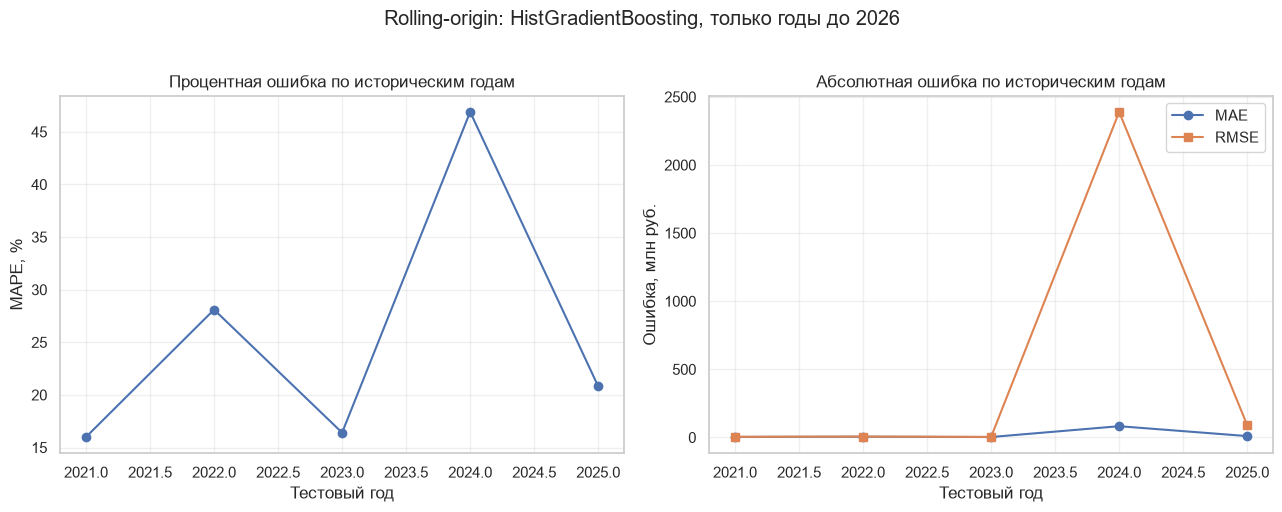

In [16]:
# Rolling-origin проверка фиксированной HistGradientBoosting.
# Для каждого года < 2026 модель обучается только на предыдущих годах.
# Данные 2026 не входят в историческую оценку качества.
from sklearn.base import clone

rolling_rows = []
rolling_years = [int(y) for y in available_years if int(y) > min(available_years)]
rolling_years = rolling_years[-5:]

for yr in rolling_years:
    tr = model_df[model_df["period_year"] < yr].copy()
    te = model_df[model_df["period_year"] == yr].copy()
    if len(tr) < 30 or len(te) < 5:
        continue
    fitted = clone(best_pipeline_fixed)
    fitted.fit(tr[feature_cols], np.log1p(tr["price"].astype(float)))
    p = np.maximum(0, np.expm1(fitted.predict(te[feature_cols])))
    a = te["price"].to_numpy()
    ape = np.abs(a-p)/np.maximum(a, 1)*100
    rolling_rows.append({
        "Тестовый год": int(yr),
        "Строк теста": len(te),
        "MAE, млн руб.": mean_absolute_error(a,p)/1e6,
        "RMSE, млн руб.": np.sqrt(mean_squared_error(a,p))/1e6,
        "MAPE, %": float(np.mean(ape)),
        "Средняя процентная точность, %": float(np.mean(np.clip(100-ape, 0, 100))),
        "R²": r2_score(a,p) if len(a)>1 else np.nan
    })

rolling_results = pd.DataFrame(rolling_rows)
if not rolling_results.empty:
    display(rolling_results.round(2))
    fig, axes = plt.subplots(1, 2, figsize=(13,5))
    axes[0].plot(rolling_results["Тестовый год"], rolling_results["MAPE, %"], marker="o")
    axes[0].set_title("Процентная ошибка по историческим годам")
    axes[0].set_xlabel("Тестовый год"); axes[0].set_ylabel("MAPE, %")
    axes[0].grid(alpha=.3)
    axes[1].plot(rolling_results["Тестовый год"], rolling_results["MAE, млн руб."], marker="o", label="MAE")
    axes[1].plot(rolling_results["Тестовый год"], rolling_results["RMSE, млн руб."], marker="s", label="RMSE")
    axes[1].set_title("Абсолютная ошибка по историческим годам")
    axes[1].set_xlabel("Тестовый год"); axes[1].set_ylabel("Ошибка, млн руб.")
    axes[1].legend(); axes[1].grid(alpha=.3)
    plt.suptitle(f"Rolling-origin: {best_model_name}, только годы до 2026", y=1.02)
    plt.tight_layout(); plt.show()
else:
    print("Недостаточно исторических данных для rolling-проверки.")

## Этап 10.0. Проверка прогноза на несколько лет вперёд на исторических периодах

Базовый прогноз цены проверяется на тестовых сделках, а для горизонта N лет отдельно запускаем исторический эксперимент: берём только сделки до выбранного года-отправной точки, обучаем уже выбранную HistGradientBoosting с найденными параметрами и предсказываем цены сделок в последующих годах. Затем сравниваем медиану фактических цен и медиану прогнозов по каждому горизонту. Все денежные значения на графиках и в таблице — полная цена квартиры в млн рублей, а процентная ошибка рассчитана отдельно.

**Ограничение интерпретации:** без ID квартиры это проверка прогноза цен будущих сделок, а не проверка изменения цены той же самой квартиры. Она показывает, насколько модель переносится на будущие годы и насколько быстро ухудшается качество при увеличении горизонта.

,Год обучения до,Год проверки,"Горизонт, лет",Сделок,"Фактическая медиана, млн руб.","Прогнозная медиана, млн руб.","MAE, млн руб.","MAPE, %","Средняя процентная точность, %"
0,2020,2021,1,7,24.08,22.08,3.75,16.00,84.00
1,2020,2022,2,1524,20.02,18.38,5.14,28.29,72.05
2,2020,2023,3,1523,20.03,18.25,5.17,28.19,72.13
3,2020,2024,4,14180,15.50,18.37,82.47,44.76,55.88
4,2020,2025,5,14891,16.30,18.38,14.09,41.28,59.03
5,2021,2022,1,1524,20.02,18.09,5.21,28.10,72.13
6,2021,2023,2,1523,20.03,17.81,5.23,27.88,72.32
7,2021,2024,3,14180,15.50,18.32,82.49,44.45,56.01
8,2021,2025,4,14891,16.30,18.28,14.08,40.93,59.28
9,2022,2023,1,1523,20.03,19.52,3.01,16.41,83.59


,"Горизонт, лет",Проверок,MAE_млн,MAPE_pct,Точность_pct
0,1,5,20.84,25.64,75.22
1,2,4,26.64,36.04,64.77
2,3,3,33.82,37.89,62.59
3,4,2,48.27,42.85,57.58
4,5,1,14.09,41.28,59.03


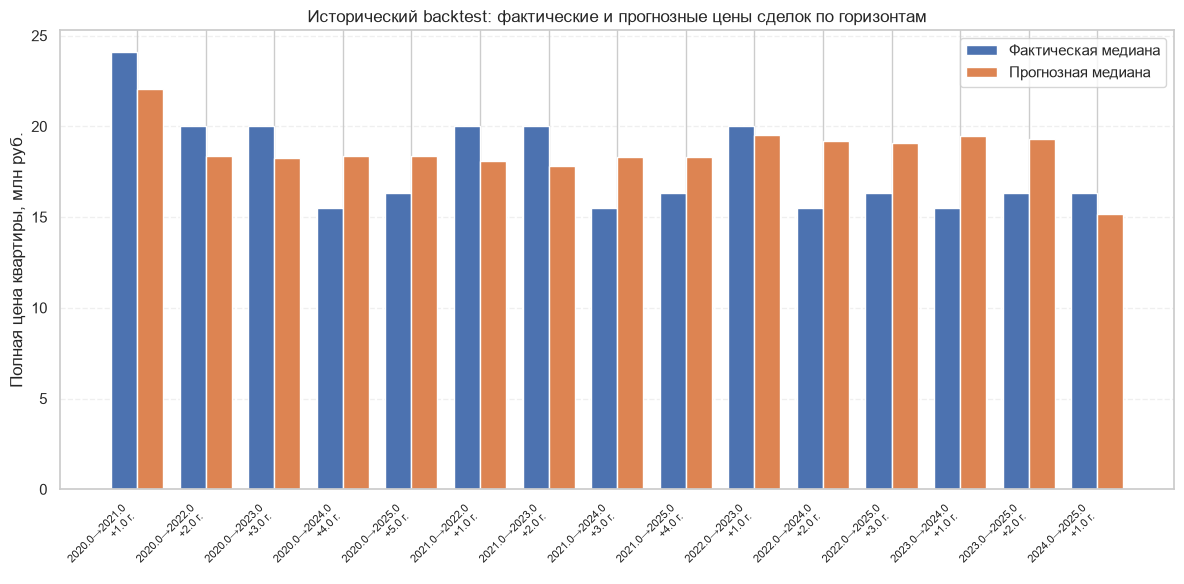

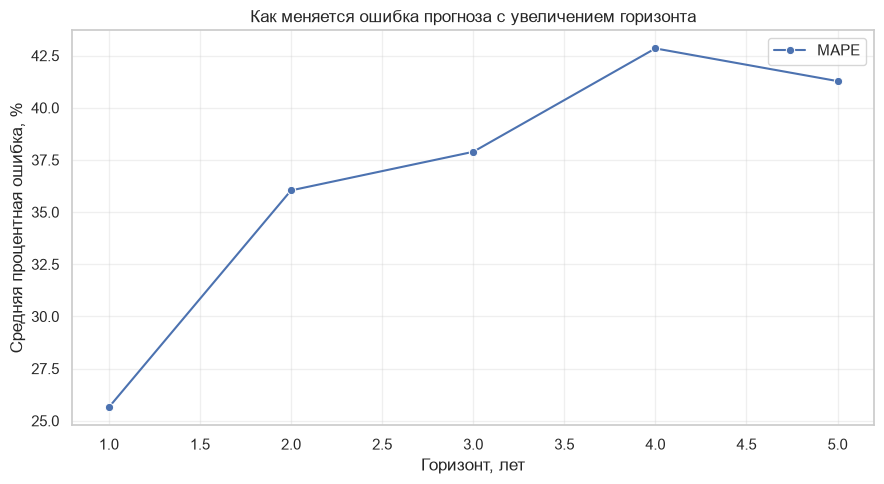

In [17]:
# Настройка горизонта проверки: можно поменять число лет.
BACKTEST_HORIZON = 5
historical_only = model_df[model_df["period_year"] < 2026].copy()
hist_years = sorted(historical_only["period_year"].dropna().astype(int).unique())
backtest_rows = []

if len(hist_years) >= 3:
    # Каждый origin — год, к концу которого модель могла бы быть обучена.
    # Для честной проверки тестовые сделки должны быть позже origin.
    origins = hist_years[:-1]
    # Чтобы время выполнения было приемлемым, используем максимум последние 5 origin years.
    origins = origins[-5:]
    for origin_year in origins:
        train_bt = historical_only[historical_only["period_year"] <= origin_year].copy()
        if len(train_bt) < 30:
            continue
        model_bt = clone(best_pipeline_fixed)
        model_bt.fit(train_bt[feature_cols], np.log1p(train_bt["price"].astype(float)))
        future_years = [y for y in hist_years if origin_year < y <= origin_year + BACKTEST_HORIZON]
        for target_year in future_years:
            test_bt = historical_only[historical_only["period_year"] == target_year].copy()
            if len(test_bt) < 5:
                continue
            pred_bt = np.maximum(0, np.expm1(model_bt.predict(test_bt[feature_cols])))
            actual_bt = test_bt["price"].to_numpy()
            ape_bt = np.abs(actual_bt-pred_bt)/np.maximum(actual_bt,1)*100
            backtest_rows.append({
                "Год обучения до": int(origin_year),
                "Год проверки": int(target_year),
                "Горизонт, лет": int(target_year-origin_year),
                "Сделок": int(len(test_bt)),
                "Фактическая медиана, млн руб.": float(np.median(actual_bt)/1e6),
                "Прогнозная медиана, млн руб.": float(np.median(pred_bt)/1e6),
                "MAE, млн руб.": float(mean_absolute_error(actual_bt,pred_bt)/1e6),
                "MAPE, %": float(np.mean(ape_bt)),
                "Средняя процентная точность, %": float(np.mean(np.clip(100-ape_bt,0,100)))
            })

backtest_n_years = pd.DataFrame(backtest_rows)
if not backtest_n_years.empty:
    display(backtest_n_years.round(2))
    summary_bt = (backtest_n_years.groupby("Горизонт, лет")
                  .agg(Проверок=("Год проверки","count"),
                       MAE_млн=("MAE, млн руб.","mean"),
                       MAPE_pct=("MAPE, %","mean"),
                       Точность_pct=("Средняя процентная точность, %","mean"))
                  .reset_index())
    display(summary_bt.round(2))

    # Для наглядности показываем прогнозные и фактические медианы по каждому историческому прогнозу.
    plot_bt = backtest_n_years.sort_values(["Год обучения до","Год проверки"]).reset_index(drop=True)
    labels_bt = [f'{r["Год обучения до"]}→{r["Год проверки"]}\n+{r["Горизонт, лет"]} г.' for _,r in plot_bt.iterrows()]
    xx = np.arange(len(plot_bt)); width=.38
    plt.figure(figsize=(max(12,len(plot_bt)*.65),6))
    plt.bar(xx-width/2, plot_bt["Фактическая медиана, млн руб."], width, label="Фактическая медиана")
    plt.bar(xx+width/2, plot_bt["Прогнозная медиана, млн руб."], width, label="Прогнозная медиана")
    plt.xticks(xx, labels_bt, rotation=45, ha="right", fontsize=8)
    plt.ylabel("Полная цена квартиры, млн руб.")
    plt.title("Исторический backtest: фактические и прогнозные цены сделок по горизонтам")
    plt.legend(); plt.grid(axis="y", linestyle="--", alpha=.3); plt.tight_layout(); plt.show()

    plt.figure(figsize=(9,5))
    sns.lineplot(data=summary_bt, x="Горизонт, лет", y="MAPE_pct", marker="o", label="MAPE")
    plt.ylabel("Средняя процентная ошибка, %")
    plt.title("Как меняется ошибка прогноза с увеличением горизонта")
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else:
    print("Для многошаговой исторической проверки недостаточно периодов или сделок.")

## Этап 10.1. Финальное обучение для практического прогноза

Историческую точность мы измеряли на данных, не участвовавших в обучении. После выбора типа модели и гиперпараметров можно переобучить её на всех доступных строках, чтобы использовать максимум информации для будущего прогноза. Это финальная модель для применения; её нельзя использовать вместо исторического теста при отчёте о точности.

In [18]:
from sklearn.base import clone
final_model = clone(best_search.best_estimator_)
final_model.fit(model_df[feature_cols], np.log1p(model_df["price"].astype(float)))
print(f"Финальная модель {best_model_name} обучена на {len(model_df):,} строках "
      f"за {model_df['period_year'].min()}–{model_df['period_year'].max()} годы.")

Финальная модель HistGradientBoosting обучена на 40,134 строках за 2015–2026 годы.


## Этап 11. Динамика рынка по каждому региону и району

Для каждой группы `region × год` и `region × district × год` вычисляем внутренний индикатор рынка — медиану цены за м², коэффициент изменения относительно предыдущего доступного года и процент изменения. В итоговых таблицах и графиках выводим только коэффициент, процент изменения и число сделок; денежные значения цены за м² остаются техническими величинами для расчёта темпа рынка. Исторические выводы ограничены годами строго меньше 2026.

In [19]:
# Цена за м² используется только как внутренний индикатор темпа рынка.
# В итоговых выводах и графиках стоимости квартиры отображаем полную цену в млн руб.
annual_region = (model_source.groupby(["region","period_year"], dropna=False)
                 .agg(median_price_per_sqm=("price_per_sqm","median"), deals=("price_per_sqm","size"))
                 .reset_index().sort_values(["region","period_year"]))
annual_region["growth_factor"] = annual_region.groupby("region")["median_price_per_sqm"].transform(lambda s: s/s.shift(1))
annual_region["growth_pct"] = (annual_region["growth_factor"]-1)*100

annual_district = (model_source.groupby(["region","district","period_year"], dropna=False)
                   .agg(median_price_per_sqm=("price_per_sqm","median"), deals=("price_per_sqm","size"))
                   .reset_index().sort_values(["region","district","period_year"]))
annual_district["growth_factor"] = annual_district.groupby(["region","district"])["median_price_per_sqm"].transform(lambda s: s/s.shift(1))
annual_district["growth_pct"] = (annual_district["growth_factor"]-1)*100

# Исторические сводки ограничиваем периодом < 2026. Данные 2026 остаются для текущего прогноза.
annual_region_historical = annual_region[annual_region["period_year"] < 2026].copy()
annual_district_historical = annual_district[annual_district["period_year"] < 2026].copy()

print("Годовые коэффициенты изменения по region (расчёт внутренне основан на цене за м²; отображаем только коэффициент и процент):")
display(annual_region_historical[["region","period_year","deals","growth_factor","growth_pct"]].round(2))
print("Годовые коэффициенты изменения по region + district:")
display(annual_district_historical[["region","district","period_year","deals","growth_factor","growth_pct"]].round(2))

region_summary = (annual_region_historical.dropna(subset=["growth_pct"])
                  .groupby("region")
                  .agg(mean_annual_growth_pct=("growth_pct","mean"),
                       median_annual_growth_pct=("growth_pct","median"),
                       latest_year=("period_year","max"),
                       total_year_changes=("growth_pct","count"),
                       min_deals_per_year=("deals","min"))
                  .reset_index().sort_values("median_annual_growth_pct",ascending=False))
district_summary = (annual_district_historical.dropna(subset=["growth_pct"])
                    .groupby(["region","district"])
                    .agg(mean_annual_growth_pct=("growth_pct","mean"),
                         median_annual_growth_pct=("growth_pct","median"),
                         latest_year=("period_year","max"),
                         total_year_changes=("growth_pct","count"),
                         min_deals_per_year=("deals","min"))
                    .reset_index().sort_values("median_annual_growth_pct",ascending=False))
print("Сводка по регионам: темп изменения в процентах, без вывода цены за м².")
display(region_summary.round(2))
print("Районы: для интерпретации используйте минимум 2 годовых изменения и достаточное число сделок.")
display(district_summary.round(2))

Годовые коэффициенты изменения по region (расчёт внутренне основан на цене за м²; отображаем только коэффициент и процент):


,region,period_year,deals,growth_factor,growth_pct
0,ВАО,2019,31,<NA>,<NA>
1,ВАО,2022,599,1.22,22.16
2,ВАО,2023,598,1.0,0.17
3,ВАО,2024,5310,0.73,-26.93
4,ВАО,2025,6131,1.07,6.58
6,НАО,2015,2,<NA>,<NA>
7,НАО,2016,35,1.25,25.28
8,НАО,2017,13,0.71,-29.3
9,САО,2018,2,<NA>,<NA>
10,САО,2019,676,2.93,193.02


Годовые коэффициенты изменения по region + district:


,region,district,period_year,deals,growth_factor,growth_pct
0,ВАО,Богородское,2019,1,<NA>,<NA>
1,ВАО,Богородское,2022,27,0.61,-38.94
2,ВАО,Богородское,2023,27,1.0,0.0
3,ВАО,Богородское,2024,495,0.82,-17.87
4,ВАО,Богородское,2025,560,1.08,8.29
...,...,...,...,...,...,...
254,ЦАО,Якиманка,2021,1,1.49,49.17
255,ЦАО,Якиманка,2022,11,1.08,7.67
256,ЦАО,Якиманка,2023,11,1.0,0.0
257,ЦАО,Якиманка,2024,220,1.41,41.19


Сводка по регионам: темп изменения в процентах, без вывода цены за м².


,region,mean_annual_growth_pct,median_annual_growth_pct,latest_year,total_year_changes,min_deals_per_year
3,ТАО,14.47,14.47,2017,1,1
4,ЦАО,16.99,14.44,2025,6,2
0,ВАО,0.49,3.38,2025,4,598
1,НАО,-2.01,-2.01,2017,2,13
2,САО,27.02,-3.43,2025,6,4


Районы: для интерпретации используйте минимум 2 годовых изменения и достаточное число сделок.


,region,district,mean_annual_growth_pct,median_annual_growth_pct,latest_year,total_year_changes,min_deals_per_year
34,ЦАО,Арбат,31.62,20.75,2025,4,11
36,ЦАО,Замоскворечье,18.49,15.53,2025,4,28
38,ЦАО,Мещанский,13.48,8.92,2025,4,25
43,ЦАО,Якиманка,21.3,8.44,2025,5,1
15,ВАО,Соколиная гора,7.32,7.32,2025,2,235
41,ЦАО,Тверской,17.43,6.14,2025,5,1
20,САО,Беговой,21.61,5.58,2025,4,27
22,САО,Войковский,3.95,4.91,2025,4,31
24,САО,Головинский,3.34,4.8,2025,4,55
39,ЦАО,Пресненский,17.12,4.62,2025,5,2


## Этап 12. Графики изменения рынка по region и district

Здесь отображается годовое процентное изменение, рассчитанное внутренне по медианному индикатору цены за м². В подписях, выводах и графиках полной стоимости не показываем цену за м². Для рейтинга районов оставляем только группы с минимум двумя годовыми изменениями и не менее чем 10 сделками в каждом доступном году — это уменьшает, но не устраняет нестабильность.

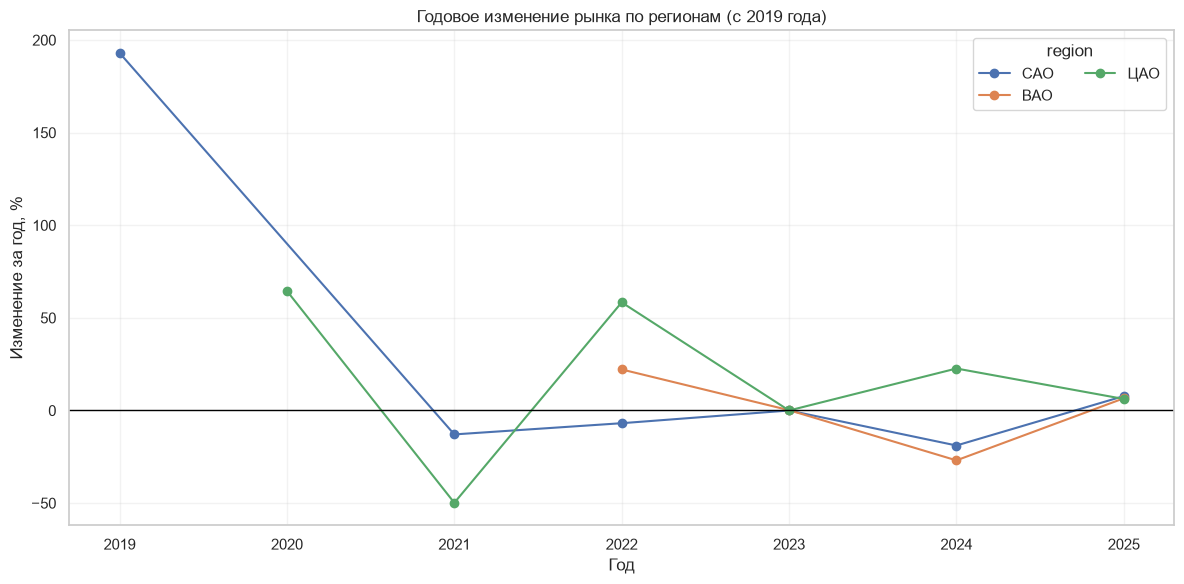

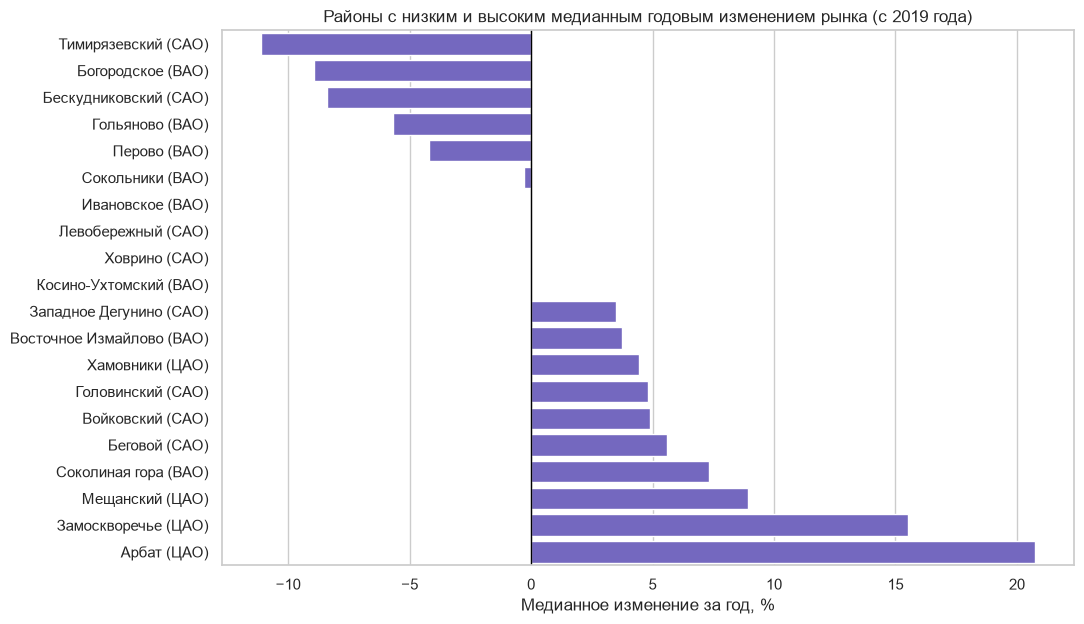

In [20]:
# Графики рыночной динамики показывают процент изменения, а не цену за м².
# Ограничиваем период с 2019 года: в более ранних годах лишь единичные сделки.
HIST_START_YEAR = 2019
region_hist_plot = annual_region_historical[annual_region_historical["period_year"] >= HIST_START_YEAR]
district_hist_plot = annual_district_historical[annual_district_historical["period_year"] >= HIST_START_YEAR]

top_regions = model_source.loc[
    (model_source["period_year"] >= HIST_START_YEAR) & (model_source["period_year"] < 2026),
    "region"
].value_counts().head(8).index.tolist()
plt.figure(figsize=(12,6))
for reg in top_regions:
    part = region_hist_plot[region_hist_plot["region"] == reg]
    plt.plot(part["period_year"], part["growth_pct"], marker="o", label=reg)
plt.axhline(0, color="black", linewidth=1)
plt.title("Годовое изменение рынка по регионам (с 2019 года)")
plt.xlabel("Год"); plt.ylabel("Изменение за год, %")
plt.legend(title="region", ncol=2); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

# Сводку по районам пересчитываем только по периоду с 2019 года.
district_summary_2019 = (district_hist_plot.dropna(subset=["growth_pct"])
                         .groupby(["region","district"])
                         .agg(mean_annual_growth_pct=("growth_pct","mean"),
                              median_annual_growth_pct=("growth_pct","median"),
                              latest_year=("period_year","max"),
                              total_year_changes=("growth_pct","count"),
                              min_deals_per_year=("deals","min"))
                         .reset_index().sort_values("median_annual_growth_pct",ascending=False))
eligible_districts = district_summary_2019[
    (district_summary_2019["total_year_changes"] >= 2) &
    (district_summary_2019["min_deals_per_year"] >= 10)
].copy()
if not eligible_districts.empty:
    ranked = pd.concat([
        eligible_districts.nsmallest(10,"median_annual_growth_pct"),
        eligible_districts.nlargest(10,"median_annual_growth_pct")
    ]).drop_duplicates()
    ranked["label"] = ranked["district"].astype(str) + " (" + ranked["region"].astype(str) + ")"
    plt.figure(figsize=(11, max(5, len(ranked)*.32)))
    sns.barplot(data=ranked.sort_values("median_annual_growth_pct"),
                x="median_annual_growth_pct", y="label", color="slateblue")
    plt.axvline(0,color="black",linewidth=1)
    plt.title("Районы с низким и высоким медианным годовым изменением рынка (с 2019 года)")
    plt.xlabel("Медианное изменение за год, %"); plt.ylabel("")
    plt.tight_layout(); plt.show()
else:
    print("Недостаточно районов с минимум двумя годовыми изменениями и минимум 10 сделками в каждом наблюдаемом году (с 2019 года).")

## Этап 13. Выбор квартиры и интерактивного горизонта прогноза

В ячейке ниже задаётся число лет `N` и характеристики квартиры. Если `ipywidgets` доступен, появятся поля ввода и кнопка «Построить прогноз». Если виджеты не поддерживаются, можно изменить значения переменных вручную и выполнить следующую ячейку. По умолчанию выбирается типичная по характеристикам сделка последнего доступного года.

In [21]:
latest_year = int(model_df["period_year"].max())
latest_rows = model_df[model_df["period_year"] == latest_year]
default_row = latest_rows.iloc[-1] if not latest_rows.empty else model_df.iloc[-1]

# Значения по умолчанию можно заменить вручную.
FORECAST_N = 5
APARTMENT = {
    "region": str(default_row["region"]),
    "district": str(default_row["district"]),
    "street": str(default_row["street"]),
    "wall_material_code": str(default_row["wall_material_code"]),
    "year_build": int(default_row["year_build"]),
    "floor": int(default_row["floor"]),
    "area": float(default_row["area"])
}

try:
    import ipywidgets as widgets
    from IPython.display import display
    interactive_forecast_available = True
    n_widget = widgets.IntSlider(value=5, min=1, max=20, step=1, description="Лет N:", continuous_update=False)
    region_widget = widgets.Dropdown(options=sorted(model_df["region"].dropna().astype(str).unique()), value=APARTMENT["region"], description="region:")
    district_options = sorted(model_df.loc[model_df["region"].astype(str)==APARTMENT["region"],"district"].dropna().astype(str).unique())
    district_widget = widgets.Dropdown(options=district_options or sorted(model_df["district"].dropna().astype(str).unique()), value=APARTMENT["district"] if APARTMENT["district"] in district_options else (district_options[0] if district_options else None), description="district:")
    area_widget = widgets.FloatText(value=APARTMENT["area"], description="Площадь м²:")
    floor_widget = widgets.IntText(value=APARTMENT["floor"], description="Этаж:")
    build_widget = widgets.IntText(value=APARTMENT["year_build"], description="Год постройки:")
    street_widget = widgets.Text(value=APARTMENT["street"], description="Улица:")
    wall_widget = widgets.Text(value=APARTMENT["wall_material_code"], description="Код стен:")
    display(widgets.VBox([n_widget, region_widget, district_widget, street_widget, area_widget, floor_widget, build_widget, wall_widget]))
except Exception as e:
    interactive_forecast_available = False
    print("Виджеты недоступны; измените FORECAST_N и APARTMENT вручную.", e)

print("Последний год в данных:", latest_year)
display(pd.DataFrame([APARTMENT]))

Последний год в данных: 2026


,region,district,street,wall_material_code,year_build,floor,area
0,ВАО,Вешняки,Старый Гай,61001007001,1971,4,33.0


## Этап 14. Прогноз цены квартиры на N лет и текстовое объяснение

Для прогноза на дальний горизонт нельзя просто подставить будущий год в дерево: деревья обычно не экстраполируют временной тренд за пределы обучающих лет. Поэтому строим базовую оценку выбранной квартиры лучшей моделью, а будущую динамику рассчитываем по CAGR медианного индикатора рынка в районе. Если у района мало истории, используем регион, затем общий рынок. Годовой темп ограничен диапазоном −15%…+25% для защиты от единичных выбросов; это сценарное допущение, а не статистически доказанный интервал.

Все отображаемые цены — **полная цена квартиры в млн рублей**, округлённая до двух знаков. Историческая точность базовой цены измеряется на сделках тестового года. Точность прогноза цены именно одной и той же квартиры через N лет нельзя проверить без идентификатора объекта и повторных наблюдений этой квартиры; график на N лет поэтому является прогнозным сценарием, а не сравнением с известной будущей ценой.

In [22]:
def safe_cagr(values, years=None):
    vals = pd.to_numeric(pd.Series(values), errors="coerce")
    if years is None:
        yrs = pd.Series(np.arange(len(vals)), index=vals.index)
    else:
        yrs = pd.to_numeric(pd.Series(years, index=vals.index), errors="coerce")
    temp = pd.DataFrame({"value": vals, "year": yrs}).dropna().sort_values("year")
    temp = temp[temp["value"] > 0]
    if len(temp) < 2:
        return np.nan
    elapsed = float(temp["year"].iloc[-1] - temp["year"].iloc[0])
    if elapsed <= 0:
        return np.nan
    return float((temp["value"].iloc[-1] / temp["value"].iloc[0]) ** (1/elapsed) - 1)

def cagr_by_year(table, year_col, value_col):
    t = table[[year_col, value_col]].dropna().sort_values(year_col)
    t = t[t[value_col] > 0]
    if len(t) < 2 or t[year_col].iloc[-1] == t[year_col].iloc[0]:
        return np.nan
    elapsed = int(t[year_col].iloc[-1] - t[year_col].iloc[0])
    return float((t[value_col].iloc[-1] / t[value_col].iloc[0]) ** (1/elapsed) - 1)

## Этап 15. Интерактивный пересчёт и сценарии роста

Если Jupyter поддерживает `ipywidgets`, можно менять горизонт и характеристики квартиры и пересчитывать прогноз кнопкой. Дополнительно строим три сценария: низкий, базовый и высокий темп роста. Сценарии — не доверительные интервалы модели, а прозрачный анализ чувствительности к предположениям о рынке.

In [23]:
if interactive_forecast_available:
    run_button = widgets.Button(description="Построить прогноз", button_style="primary")
    output = widgets.Output()
    def on_run_clicked(_):
        with output:
            output.clear_output(wait=True)
            apt = {"region":region_widget.value, "district":district_widget.value or APARTMENT["district"],
                   "street":street_widget.value, "wall_material_code":wall_widget.value,
                   "year_build":build_widget.value, "floor":floor_widget.value, "area":area_widget.value}
            build_forecast(apt, n_widget.value)
    run_button.on_click(on_run_clicked)
    display(run_button, output)
else:
    print("Интерактивные виджеты не установлены. Для ручного пересчёта измените FORECAST_N/APARTMENT и запустите ячейку этапа 14.")

# Сценарии +/- 5 процентных пунктов от оценённого базового роста.
if "forecast_result" in globals():
    base_prices = forecast_result["Прогноз цены, руб."].to_numpy()
    base_growth = 0.0
    if len(base_prices) > 1 and base_prices[0] > 0:
        base_growth = (base_prices[1]/base_prices[0])-1
    years_s = forecast_result["Год"].to_numpy()
    base_p = base_prices[0]
    scenario = pd.DataFrame({
        "Год":years_s,
        "Низкий сценарий, млн руб.":[base_p*(1+base_growth-0.05)**h/1e6 for h in range(len(years_s))],
        "Базовый сценарий, млн руб.":[base_p*(1+base_growth)**h/1e6 for h in range(len(years_s))],
        "Высокий сценарий, млн руб.":[base_p*(1+base_growth+0.05)**h/1e6 for h in range(len(years_s))]
    })
    display(scenario.round(2))
    plt.figure(figsize=(10,5))
    for col in scenario.columns[1:]:
        plt.plot(scenario["Год"], scenario[col], marker="o", label=col)
    plt.title("Чувствительность прогноза к темпу роста рынка")
    plt.xlabel("Год"); plt.ylabel("Цена, млн руб."); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.show()

Button(button_style='primary', description='Построить прогноз', style=ButtonStyle())

Output()

## Этап 16. Итоговая интерпретация и сохранение результатов

Последняя ячейка автоматически формирует текстовый вывод о лучшей модели, её ошибках, доступной истории и ограничениях прогноза. Сохраняем таблицы годовой динамики и сравнительные метрики в CSV, чтобы их можно было использовать в отчёте.

In [24]:
winner = model_comparison.iloc[0]
print("ИТОГ")
print(f"Выбранная модель: {best_model_name}. Исторический тестовый год: {test_year}.")
print(f"MAE = {fixed_mae/1e6:.2f} млн руб.; RMSE = {fixed_rmse/1e6:.2f} млн руб.; "
      f"MAPE = {fixed_mape:.2f}%; средняя процентная точность по формуле max(0, 100−APE) = "
      f"{np.mean(np.clip(100-np.abs(actual_fixed_test-pred_fixed_test)/np.maximum(actual_fixed_test,1)*100,0,100)):.2f}%; "
      f"R² = {fixed_r2:.3f}.")
print("Процентная точность — вспомогательная метрика; MAPE показывает среднюю процентную ошибку и предпочтительнее для сравнения.")
print(f"Исторические данные для основного теста ограничены годами строго до 2026; текущий набор охватывает "
      f"{model_source['period_year'].min()}–{model_source['period_year'].max()}.")
print("Рост рынка оценивается внутри кода по медианным значениям цены за м², но выводы и графики стоимости показывают полную цену квартиры в млн руб.")
print("Ограничение: без ID одной и той же квартиры нельзя доказать, насколько точно изменилась цена именно этого объекта через N лет. Для этого нужна повторная история того же объекта.")
for fname, frame in [
    ("model_comparison.csv", model_comparison.drop(columns=["Лучшие параметры"], errors="ignore")),
    ("annual_region_growth.csv", annual_region),
    ("annual_district_growth.csv", annual_district),
    ("rolling_results.csv", rolling_results if "rolling_results" in globals() else pd.DataFrame()),
    ("backtest_n_years.csv", backtest_n_years if "backtest_n_years" in globals() else pd.DataFrame())
]:
    frame.to_csv(fname, index=False, encoding="utf-8-sig")
print("Сохранены таблицы: model_comparison.csv, annual_region_growth.csv, annual_district_growth.csv, rolling_results.csv, backtest_n_years.csv")

NameError: name 'model_comparison' is not defined